# 04 · Interpretación de los segmentos

En el reto 3 nos quedamos con 7 grupos de clientes. Ahora toca lo más importante: **entender quién hay en cada uno y qué haríamos con ellos**. Lo que pide el reto es un perfil de cada cluster que un equipo de marketing pueda usar, y un nombre descriptivo para cada uno.

Cómo lo vamos a hacer: siempre comparamos **cada segmento con el total de clientes**. Que un segmento tenga 48 meses de antigüedad no dice nada; que tenga 48 cuando la media es 34 ya es un rasgo.

Todas las cifras salen de `src/profiling.py`, que es lo mismo que usa el dashboard. Así es imposible que el notebook y el dashboard digan cosas distintas. Los nombres, frases y planes los escribimos nosotros en `src/segmentos.py`, pero sin números a mano: llevan huecos que se rellenan con el dato.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from src import config, clean, clustering, profiling
from src.profiling import KPIS, fmt_kpi
from src.segmentos import SEGMENTOS, fill_texts, check_segmentos

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
COLORES = config.SEGMENT_COLORS

## 1. Cargamos los clientes y su segmento

Usamos la tabla de clientes del reto 2 y las etiquetas que guardó el reto 3 (`outputs/labels_final.csv`). No re-entrenamos nada.

In [2]:
clientes = clean.load_clients()
etiquetas = clustering.load_labels()

perfil = profiling.build_profile(clientes, etiquetas)
profiling.check_profile(perfil)  # los tamaños suman el total y cada distribución suma 100 %
check_segmentos(SEGMENTOS, perfil["meta"]["k"])  # cada segmento tiene nombre, frase y plan

base = perfil["base"]
segs = perfil["segmentos"]
nombres = [SEGMENTOS[s["id"]]["nombre"] for s in segs]
print(f"{perfil['meta']['n']:,} clientes en {perfil['meta']['k']} segmentos")

173,456 clientes en 7 segmentos


Antes de seguir comprobamos que el perfil cuadra con lo que vimos en el reto 3 (el "primer vistazo" de allí). Si alguien re-entrenara el modelo y cambiaran los grupos, esta celda fallaría y nos daríamos cuenta antes de presentar perfiles equivocados.

In [3]:
assert [s["n"] for s in segs] == [41811, 31769, 31611, 27575, 15660, 15327, 9703]
antiguedad_03 = [47.99, 17.74, 32.25, 29.25, 17.36, 54.34, 39.09]
assert all(abs(s["kpis"]["antiguedad_meses"] - a) < 0.01 for s, a in zip(segs, antiguedad_03))
print("El perfil reproduce el reto 3")

El perfil reproduce el reto 3


## 2. Cuánto pesa cada segmento

Ya les ponemos los nombres que hemos decidido (en la sección 6 explicamos de dónde sale cada uno).

In [4]:
tamanos = pd.DataFrame({"segmento": nombres, "clientes": [s["n"] for s in segs],
                        "%": [round(s["pct"], 1) for s in segs]})
tamanos

,segmento,clientes,%
0,Fieles de taller,41811,24.1
1,Recién llegados,31769,18.3
2,Coche veterano,31611,18.2
3,Electrificados,27575,15.9
4,Desconectados,15660,9.0
5,Multivehículo,15327,8.8
6,Zonas premium,9703,5.6


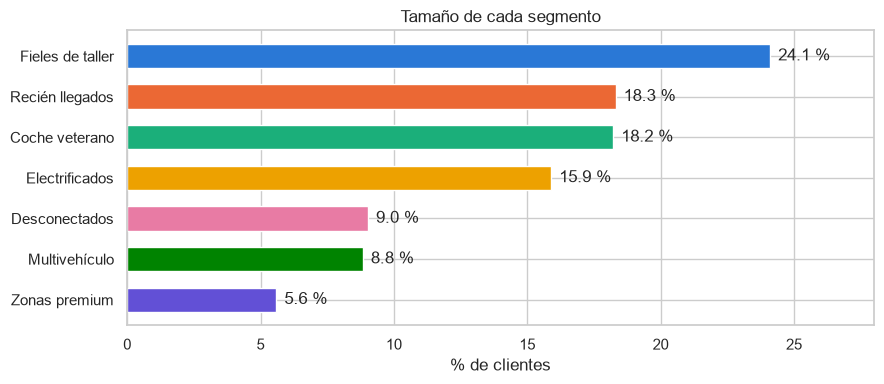

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(nombres[::-1], [s["pct"] for s in segs][::-1], color=COLORES[::-1], height=0.6)
for i, s in enumerate(segs[::-1]):
    ax.text(s["pct"] + 0.3, i, f"{s['pct']:.1f} %", va="center")
ax.set_xlabel("% de clientes")
ax.set_title("Tamaño de cada segmento")
ax.set_xlim(0, 28)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "04_tamanos.png", dpi=110)
plt.show()

## 3. Qué distingue a cada segmento

Este es el gráfico más importante del notebook. Para cada segmento y cada indicador miramos **cuánto se separa de la media**, medido en desviaciones típicas (lo que en el reto 3 llamábamos z). Rojo es por encima de la media y azul por debajo; cuanto más intenso, más diferente. Dentro de cada casilla ponemos el valor real del segmento, para que se lea sin traducir.

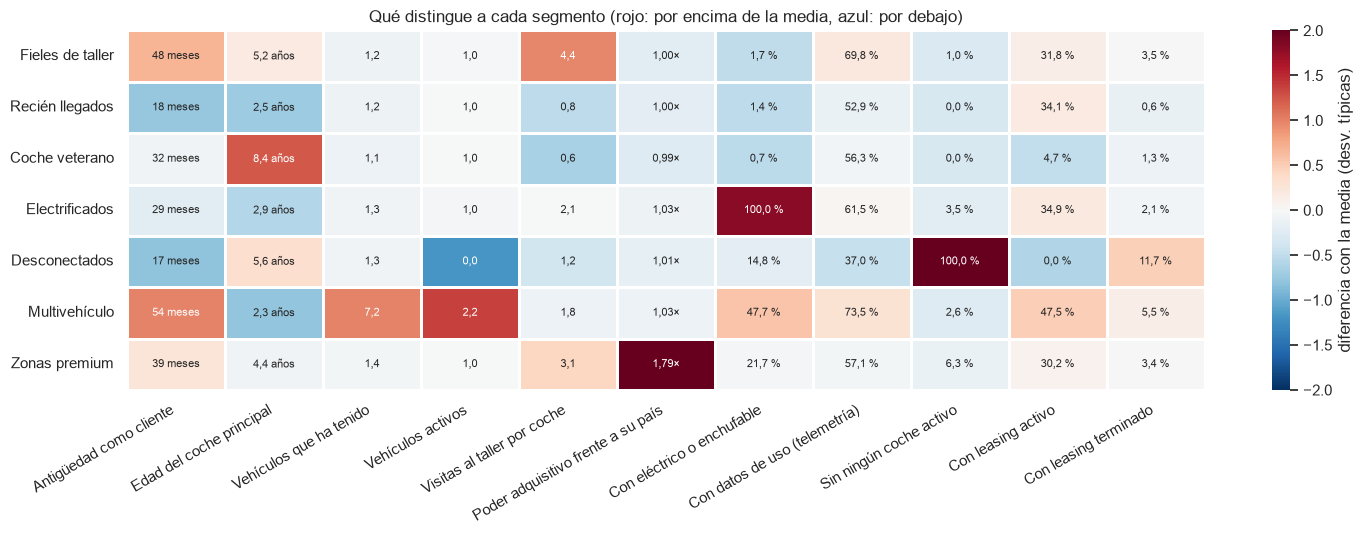

In [6]:
z = pd.DataFrame([s["z"] for s in segs], index=nombres)[list(KPIS)]
valores = pd.DataFrame([[fmt_kpi(k, s["kpis"][k]) for k in KPIS] for s in segs], index=nombres, columns=list(KPIS))
z.columns = valores.columns = [KPIS[k]["label"] for k in KPIS]

fig, ax = plt.subplots(figsize=(15, 5.5))
sns.heatmap(z, annot=valores, fmt="", cmap="RdBu_r", center=0, vmin=-2, vmax=2, linewidths=1,
            cbar_kws={"label": "diferencia con la media (desv. típicas)"}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Qué distingue a cada segmento (rojo: por encima de la media, azul: por debajo)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "04_mapa_calor.png", dpi=110)
plt.show()

Leyéndolo por filas, cada segmento tiene una o dos casillas muy marcadas que lo definen:

- **Coche en garantía:** las visitas en garantía y la antigüedad, muy por encima.
- **Recién llegados:** antigüedad y edad del coche, muy por debajo.
- **Coche veterano:** la edad del coche, la más alta de todas.
- **Electrificados:** la electrificación, que es su seña de identidad.
- **Desconectados:** sin vehículos activos (todos).
- **Multivehículo:** nº de vehículos y vehículos activos.
- **Zonas premium:** el poder adquisitivo relativo. Es, junto con el "sin coche activo" de los Desconectados, la casilla más intensa del mapa.

Y hay columnas que casi no cambian de color, como la de datos de uso (solo destaca algo en Desconectados). Eso también es información: no es lo que separa a los clientes.

## 4. ¿Por qué no hay un segmento de furgonetas?

Es una pregunta que nos hicimos nosotros mismos, porque en el EDA vimos un bloque importante de furgonetas (Vito, Sprinter...). Miramos qué clase de coche lleva cada segmento frente al total:

In [7]:
clase = pd.DataFrame({n: s["dist"]["clase"] for n, s in zip(nombres, segs)}).T
clase.loc["TOTAL"] = base["dist"]["clase"]
clase.round(1)

,COMPACTO,MEDIO,FURGONETA,EJECUTIVO,SUV_GRANDE,LUJO_DEPORTIVO,OTRO
Fieles de taller,39.5,30.2,11.4,7.1,8.3,3.4,0.1
Recién llegados,37.2,28.3,20.6,5.3,5.5,2.3,0.7
Coche veterano,36.0,33.0,5.7,15.6,5.7,4.0,0.0
Electrificados,37.0,31.5,0.4,13.1,9.8,3.6,4.6
Desconectados,37.3,28.7,10.3,10.7,6.7,5.3,0.9
Multivehículo,22.7,26.6,19.9,10.5,9.5,7.2,3.7
Zonas premium,30.0,31.0,7.6,9.7,12.0,8.5,1.2
TOTAL,35.8,30.2,10.7,10.0,7.7,4.1,1.3


Las furgonetas están algo concentradas en Recién llegados y Multivehículo (alrededor del 20 %, frente al 11 % del total), pero en ningún segmento son mayoría. La clase de coche cambia poco de un segmento a otro.

La razón es una decisión que tomamos en el reto 2: las variables de tipo sí/no (clase de coche, motor, financiación) las dejamos en 0/1 sin escalar, para que no acapararan el modelo. Por eso pesan menos que las numéricas, y **los segmentos quedan definidos por la relación con la marca y el ciclo de vida del coche** (antigüedad, edad del coche, actividad, electrificación...), no por el producto.

Nos parece una segmentación más útil para marketing: dice **cuándo y cómo** hablarle a cada cliente (renovar, recuperar, fidelizar). El producto que se le ofrece se ajusta dentro de cada segmento con estas tablas.

## 5. Por dónde podemos hablarles

In [8]:
canales = pd.DataFrame({n: s["canales"] for n, s in zip(nombres, segs)}).T
canales.loc["TOTAL"] = base["canales"]
canales.round(1)

,telefono,email,correo
Fieles de taller,86.6,98.4,85.6
Recién llegados,86.5,98.4,84.7
Coche veterano,87.2,98.2,86.6
Electrificados,84.5,98.5,83.6
Desconectados,86.2,97.8,86.0
Multivehículo,84.7,98.3,85.0
Zonas premium,84.9,97.8,84.5
TOTAL,86.1,98.3,85.2


Los consentimientos son prácticamente iguales en todos los segmentos: el email lo tiene casi todo el mundo, y teléfono y correo postal rondan el 85 %. Por eso no los metimos en el modelo (dicen por dónde contactar, no quién es el cliente). Para marketing la conclusión es sencilla: **el email llega a todos**, y el canal se elige por el tipo de mensaje, no por el segmento.

## 6. Ficha de cada segmento

Para cada segmento enseñamos lo mismo, en el mismo orden:

1. La ficha: nombre, tamaño, una frase de quién es, sus rasgos y el plan de acción en las cuatro palancas que pide el reto (oferta de vehículo, mantenimiento, fidelización y comunicación), más qué mediríamos para saber si funciona.
2. La tabla de indicadores: valor del segmento, valor del total y la diferencia.
3. El gráfico de diferencias con la media, ordenado de más a menos distinto.

Debajo de cada una explicamos por qué le hemos puesto ese nombre. Las reglas que seguimos para los nombres: dos o tres palabras, que describan el comportamiento y no la demografía, que se entiendan sin saber qué es K-Means y que no juzguen al cliente.

In [9]:
PALANCAS = {"objetivo": "Objetivo", "oferta": "Oferta de vehículo", "mantenimiento": "Mantenimiento",
            "fidelizacion": "Fidelización", "comunicacion": "Comunicación", "medir": "Qué medimos"}


def ficha(seg_id):
    s = segs[seg_id]
    t = fill_texts(SEGMENTOS[seg_id], s)
    plan = "\n".join(f"| {PALANCAS[k]} | {v} |" for k, v in t["plan"].items())
    display(Markdown(
        f"### {t['nombre']} · {t['accion']}\n"
        f"**{s['n']:,} clientes ({s['pct']:.1f} %)**\n\n> {t['frase']}\n\n"
        f"**Rasgos:** {' · '.join(t['etiquetas'])}\n\n| Palanca | Qué hacemos |\n|---|---|\n{plan}"
    ))
    tabla = pd.DataFrame({
        "segmento": [fmt_kpi(k, s["kpis"][k]) for k in KPIS],
        "total": [fmt_kpi(k, base["kpis"][k]) for k in KPIS],
        "diferencia (desv.)": [round(s["z"][k], 2) for k in KPIS],
    }, index=[KPIS[k]["label"] for k in KPIS])
    display(tabla)

    zs = pd.Series(s["z"]).rename(lambda k: KPIS[k]["label"])
    zs = zs.reindex(zs.abs().sort_values().index)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(zs.index, zs.values, color=[COLORES[seg_id] if abs(v) >= 0.5 else config.BASE_GRAY for v in zs.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{t['nombre']}: diferencia con la media (desv. típicas)")
    plt.tight_layout()
    plt.savefig(config.FIG_DIR / f"04_ficha_{t['slug']}.png", dpi=110)
    plt.show()

### Fieles de taller · Fidelizar
**41,811 clientes (24.1 %)**

> Clientes de hace tiempo (48 meses de media) que pasan por el taller más que nadie: 4,4 visitas por coche. Casi no tienen coches electrificados.

**Rasgos:** 4,4 visitas al taller por coche · 48 meses con nosotros · solo 1,7 % electrificados

| Palanca | Qué hacemos |
|---|---|
| Objetivo | Mantener y premiar su relación con el servicio oficial, que es lo que los define. |
| Oferta de vehículo | Renovación con prioridad y valoración de su coche actual cuando se acerque el cambio; primera prueba de un híbrido, porque casi no tienen. |
| Mantenimiento | Contrato de mantenimiento con precio cerrado: ya vienen mucho al taller y así les damos tranquilidad y nos aseguramos de que sigan viniendo. |
| Fidelización | Ventajas por antigüedad: revisiones prioritarias, coche de sustitución, regalos de aniversario como clientes. |
| Comunicación | Email y teléfono con un tono de agradecimiento por su confianza; recordatorios de servicio personalizados. |
| Qué medimos | Contratos de mantenimiento firmados y cuántos siguen viniendo al taller oficial. |

,segmento,total,diferencia (desv.)
Antigüedad como cliente,48 meses,34 meses,0.68
Edad del coche principal,"5,2 años","4,6 años",0.17
Vehículos que ha tenido,"1,2","1,7",-0.09
Vehículos activos,"1,0","1,0",-0.02
Visitas al taller por coche,"4,4","2,1",0.98
Poder adquisitivo frente a su país,"1,00×","1,05×",-0.23
Con eléctrico o enchufable,"1,7 %","23,4 %",-0.51
Con datos de uso (telemetría),"69,8 %","59,6 %",0.21
Sin ningún coche activo,"1,0 %","10,4 %",-0.31
Con leasing activo,"31,8 %","26,2 %",0.13


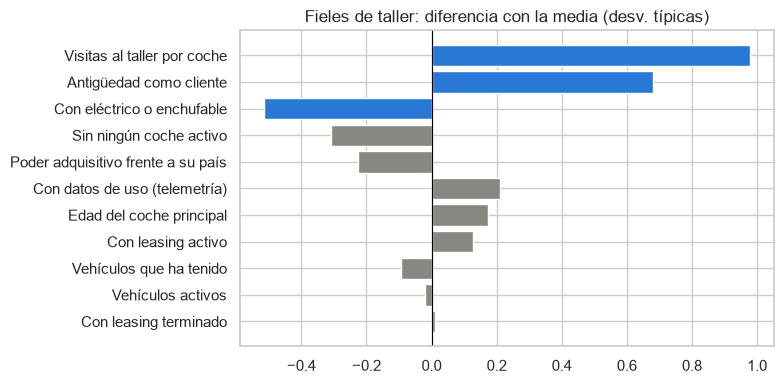

In [10]:
ficha(0)

**Por qué este nombre.** Lo que más les separa de la media son las **visitas en garantía** (el doble que la media) y la **antigüedad** (unos 14 meses más). Ojo con la primera: solo cuenta las visitas al taller durante la garantía, y esas se hacen en el taller oficial por obligación, así que no mide fidelidad. Lo que sí nos dice es que su coche (unos 5 años) está en la edad en que más se usa la garantía y en la que se acaba. De ahí "coche en garantía": son clientes a los que hay que retener en el taller oficial cuando se queden sin cobertura. Casi no tienen coches electrificados, que es la otra oportunidad.

### Recién llegados · Vincular
**31,769 clientes (18.3 %)**

> Llevan poco con nosotros (18 meses) y tienen un coche casi nuevo (2,5 años). Todavía apenas han pisado el taller.

**Rasgos:** 18 meses como clientes · coche de 2,5 años · 0,8 visitas al taller por coche

| Palanca | Qué hacemos |
|---|---|
| Objetivo | Convertir la primera compra en una relación: que vuelvan al taller oficial y que su próximo coche también sea un Mercedes. |
| Oferta de vehículo | Todavía no es momento de cambiar de coche: accesorios, extensiones de garantía y servicios conectados. |
| Mantenimiento | Primera revisión con cita propuesta por nosotros, para que la hagan en el taller oficial. |
| Fidelización | Programa de bienvenida durante el primer año: activar la app y los servicios conectados, y una experiencia de entrega cuidada. |
| Comunicación | Email con una secuencia de bienvenida; mensajes cortos y prácticos sobre su coche. |
| Qué medimos | Cuántos hacen la primera revisión en el taller oficial y cuántos activan la app. |

,segmento,total,diferencia (desv.)
Antigüedad como cliente,18 meses,34 meses,-0.78
Edad del coche principal,"2,5 años","4,6 años",-0.72
Vehículos que ha tenido,"1,2","1,7",-0.10
Vehículos activos,"1,0","1,0",-0.00
Visitas al taller por coche,"0,8","2,1",-0.53
Poder adquisitivo frente a su país,"1,00×","1,05×",-0.21
Con eléctrico o enchufable,"1,4 %","23,4 %",-0.52
Con datos de uso (telemetría),"52,9 %","59,6 %",-0.14
Sin ningún coche activo,"0,0 %","10,4 %",-0.34
Con leasing activo,"34,1 %","26,2 %",0.18


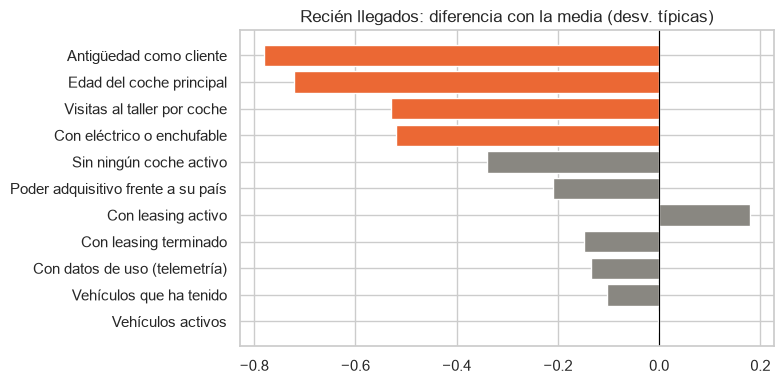

In [11]:
ficha(1)

**Por qué este nombre.** Están entre los que **menos tiempo llevan** con la marca (solo los Desconectados llevan menos) y tienen un **coche casi nuevo**; todavía han usado poco la garantía. "Recién llegados" lo dice tal cual. El reto con ellos es que la primera compra no sea la única.

### Coche veterano · Renovar
**31,611 clientes (18.2 %)**

> Tienen el coche más antiguo de la cartera (8,4 años), sobre todo de combustión y comprado sin leasing. Ojo: en muchos la antigüedad como cliente es un valor por defecto, así que pueden llevar con nosotros más tiempo del que dice el dato.

**Rasgos:** coche de 8,4 años · solo 4,7 % con leasing · 0,6 visitas al taller por coche

| Palanca | Qué hacemos |
|---|---|
| Objetivo | Que cuando cambien de coche, el siguiente sea un Mercedes. |
| Oferta de vehículo | Renovación con buena valoración de su coche actual; financiación o leasing, que casi no han probado; seminuevos certificados para los más jóvenes del grupo. |
| Mantenimiento | Revisión específica para coches con años: mantenerlos en el taller oficial hasta que llegue el cambio. |
| Fidelización | Invitación a probar los modelos actuales (incluidos híbridos) para que vean el salto. |
| Comunicación | Email y correo postal con ofertas de renovación concretas. |
| Qué medimos | Pruebas de conducción solicitadas y renovaciones cerradas. |

,segmento,total,diferencia (desv.)
Antigüedad como cliente,32 meses,34 meses,-0.08
Edad del coche principal,"8,4 años","4,6 años",1.24
Vehículos que ha tenido,"1,1","1,7",-0.11
Vehículos activos,"1,0","1,0",-0.02
Visitas al taller por coche,"0,6","2,1",-0.64
Poder adquisitivo frente a su país,"0,99×","1,05×",-0.25
Con eléctrico o enchufable,"0,7 %","23,4 %",-0.54
Con datos de uso (telemetría),"56,3 %","59,6 %",-0.07
Sin ningún coche activo,"0,0 %","10,4 %",-0.34
Con leasing activo,"4,7 %","26,2 %",-0.49


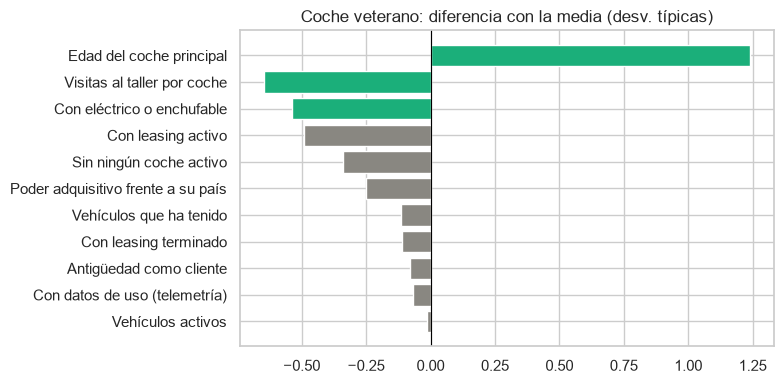

In [12]:
ficha(2)

**Por qué este nombre.** Su rasgo más fuerte es la **edad del coche**, la más alta de todos los segmentos (casi el doble que la media), y casi ninguno ha usado leasing. Es el grupo que tiene el cambio de coche más cerca, por eso "coche veterano" y la acción es renovar. Además, más de la mitad no tiene ninguna visita en garantía: su coche ya ha salido de ella (o la tuvo con otro dueño) y no vemos que pase por el taller oficial. Por eso el plan incluye traerlos al taller antes de que toque cambiar de coche. Un aviso: en este segmento hay muchos clientes con la antigüedad por defecto de 36 meses que vimos en el EDA, así que probablemente llevan con nosotros más tiempo del que dice el dato.

### Electrificados · Acompañar
**27,575 clientes (15.9 %)**

> Ya se han pasado a la electrificación: prácticamente todos (100,0 %) tienen un eléctrico o un enchufable, con un coche reciente (2,9 años). Son algo mayores que la media.

**Rasgos:** 100,0 % con eléctrico o enchufable · coche de 2,9 años · 34,9 % con leasing activo

| Palanca | Qué hacemos |
|---|---|
| Objetivo | Que su siguiente coche siga siendo eléctrico y Mercedes, y cuidar su experiencia de carga. |
| Oferta de vehículo | Siguiente eléctrico de la gama EQ; paso de enchufable a eléctrico puro al terminar su leasing. |
| Mantenimiento | Revisión específica de batería y sistema de carga; instalación y revisión del wallbox. |
| Fidelización | Ventajas en carga pública y servicios conectados pensados para eléctricos. |
| Comunicación | Email con contenido práctico sobre carga, autonomía y novedades eléctricas. |
| Qué medimos | Cuántos repiten con un eléctrico y cuánto usan los servicios de carga. |

,segmento,total,diferencia (desv.)
Antigüedad como cliente,29 meses,34 meses,-0.22
Edad del coche principal,"2,9 años","4,6 años",-0.59
Vehículos que ha tenido,"1,3","1,7",-0.09
Vehículos activos,"1,0","1,0",-0.04
Visitas al taller por coche,"2,1","2,1",-0.00
Poder adquisitivo frente a su país,"1,03×","1,05×",-0.10
Con eléctrico o enchufable,"100,0 %","23,4 %",1.81
Con datos de uso (telemetría),"61,5 %","59,6 %",0.04
Sin ningún coche activo,"3,5 %","10,4 %",-0.23
Con leasing activo,"34,9 %","26,2 %",0.20


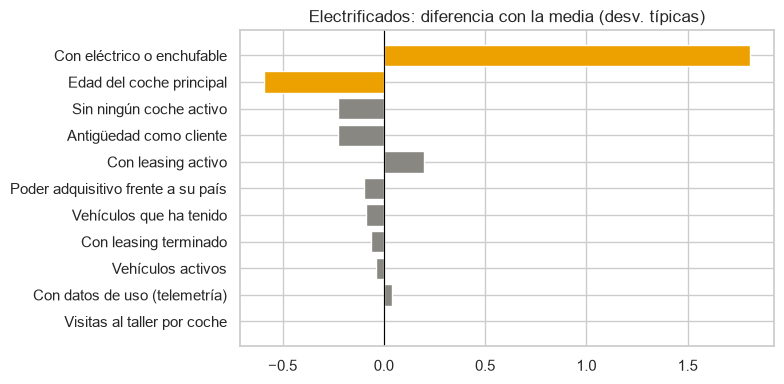

In [13]:
ficha(3)

**Por qué este nombre.** Aquí no hay duda: todos tienen un **eléctrico o un enchufable**, mientras que en el total es menos de uno de cada cuatro. Tienen coche reciente y son algo mayores que la media, lo que confirma lo que vimos en el EDA: quien se pasa al eléctrico no es el cliente más joven.

### Desconectados · Recuperar
**15,660 clientes (9.0 %)**

> Han tenido coche con nosotros, pero hoy no tienen ninguno activo. Eso no prueba que se hayan ido (pueden haberlo vendido o desvinculado), pero es la señal de alarma más clara. El 11,7 % tiene un leasing ya terminado.

**Rasgos:** 100,0 % sin coche activo · 17 meses como clientes · 11,7 % con leasing terminado

| Palanca | Qué hacemos |
|---|---|
| Objetivo | Averiguar quién se ha ido de verdad y recuperar a los que todavía se puede. |
| Oferta de vehículo | Oferta de vuelta para quienes terminaron su leasing: un coche nuevo con condiciones de reenganche. |
| Mantenimiento | Si aún tienen el coche, invitación a una revisión en el taller oficial. |
| Fidelización | Encuesta corta de por qué ya no tienen coche activo, para aprender y personalizar. |
| Comunicación | Teléfono para los que terminaron leasing y email para el resto; tono cercano, sin presión. |
| Qué medimos | Cuántos vuelven a tener un vehículo activo. |

,segmento,total,diferencia (desv.)
Antigüedad como cliente,17 meses,34 meses,-0.80
Edad del coche principal,"5,6 años","4,6 años",0.33
Vehículos que ha tenido,"1,3","1,7",-0.09
Vehículos activos,"0,0","1,0",-1.18
Visitas al taller por coche,"1,2","2,1",-0.39
Poder adquisitivo frente a su país,"1,01×","1,05×",-0.17
Con eléctrico o enchufable,"14,8 %","23,4 %",-0.20
Con datos de uso (telemetría),"37,0 %","59,6 %",-0.46
Sin ningún coche activo,"100,0 %","10,4 %",2.93
Con leasing activo,"0,0 %","26,2 %",-0.60


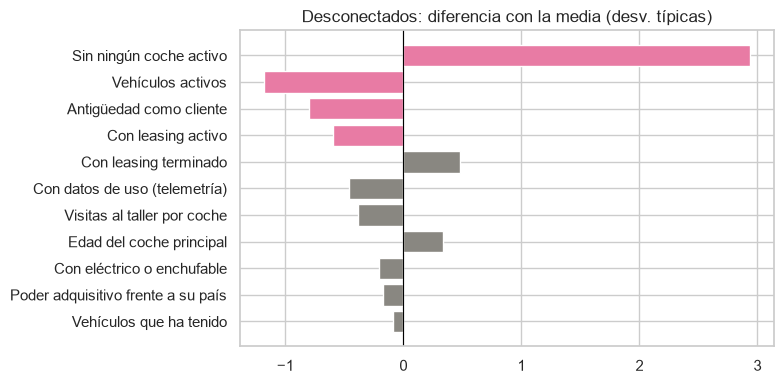

In [14]:
ficha(4)

**Por qué este nombre.** Lo que les define es que **no tienen ningún vehículo activo**. Les llamamos "desconectados" y no "perdidos" a propósito: no tener coche activo no prueba que se hayan ido (pueden haberlo vendido, desvinculado de la app...). Pero es la señal de alarma más clara que tenemos, y además aquí se concentran los leasing terminados.

### Multivehículo · Ampliar
**15,327 clientes (8.8 %)**

> Tienen muchos coches (7,2 de media) y son los clientes más antiguos (54 meses). Aquí están casi todas las flotas y cuentas grandes, y son los que más usan el leasing.

**Rasgos:** 7,2 vehículos de media · 54 meses con nosotros · 47,5 % con leasing activo

| Palanca | Qué hacemos |
|---|---|
| Objetivo | Tratarlos como cuentas clave y crecer dentro de cada una. |
| Oferta de vehículo | Renovación de flota con condiciones por volumen, incluidas furgonetas y eléctricos para empresa. |
| Mantenimiento | Contrato de mantenimiento de flota con un único punto de contacto. |
| Fidelización | Un gestor de cuenta y condiciones que mejoran con el tiempo. |
| Comunicación | Teléfono, con su gestor de cuenta; nada de campañas masivas. |
| Qué medimos | Vehículos renovados por cuenta y cuentas que siguen con nosotros. |

,segmento,total,diferencia (desv.)
Antigüedad como cliente,54 meses,34 meses,0.99
Edad del coche principal,"2,3 años","4,6 años",-0.79
Vehículos que ha tenido,"7,2","1,7",0.99
Vehículos activos,"2,2","1,0",1.37
Visitas al taller por coche,"1,8","2,1",-0.11
Poder adquisitivo frente a su país,"1,03×","1,05×",-0.11
Con eléctrico o enchufable,"47,7 %","23,4 %",0.57
Con datos de uso (telemetría),"73,5 %","59,6 %",0.28
Sin ningún coche activo,"2,6 %","10,4 %",-0.26
Con leasing activo,"47,5 %","26,2 %",0.49


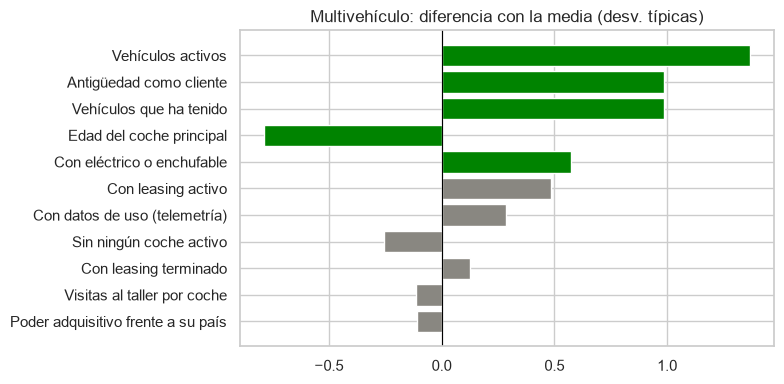

In [15]:
ficha(5)

**Por qué este nombre.** Tienen **muchos más vehículos** que nadie y son los **clientes más antiguos**. Aquí caen casi todas las cuentas grandes (904 de las 908 con 20 o más vehículos), pero también familias con varios coches, por eso es el segmento más variado (el de silhouette más bajo en el reto 3). "Multivehículo" describe lo que tienen en común sin dar por hecho que todos son empresas.

### Zonas premium · Elevar
**9,703 clientes (5.6 %)**

> Viven en las zonas más ricas de su país (1,79× el poder adquisitivo típico), casi todos en Suiza, y van mucho al taller. Más gama alta que la media.

**Rasgos:** 1,79× la riqueza de su país · 3,1 visitas al taller por coche · 30,2 % con leasing activo

| Palanca | Qué hacemos |
|---|---|
| Objetivo | Subirles de gama y darles un trato a la altura. |
| Oferta de vehículo | Modelos de gama alta (Clase S, EQS, AMG, Clase G) y configuraciones a medida. |
| Mantenimiento | Servicio premium: recogida y entrega del coche en casa. |
| Fidelización | Eventos y experiencias exclusivas, acceso anticipado a lanzamientos. |
| Comunicación | Teléfono con un asesor personal y correo postal cuidado. |
| Qué medimos | Cuántos suben de gama y el valor medio de su compra. |

,segmento,total,diferencia (desv.)
Antigüedad como cliente,39 meses,34 meses,0.25
Edad del coche principal,"4,4 años","4,6 años",-0.09
Vehículos que ha tenido,"1,4","1,7",-0.06
Vehículos activos,"1,0","1,0",-0.01
Visitas al taller por coche,"3,1","2,1",0.43
Poder adquisitivo frente a su país,"1,79×","1,05×",2.91
Con eléctrico o enchufable,"21,7 %","23,4 %",-0.04
Con datos de uso (telemetría),"57,1 %","59,6 %",-0.05
Sin ningún coche activo,"6,3 %","10,4 %",-0.13
Con leasing activo,"30,2 %","26,2 %",0.09


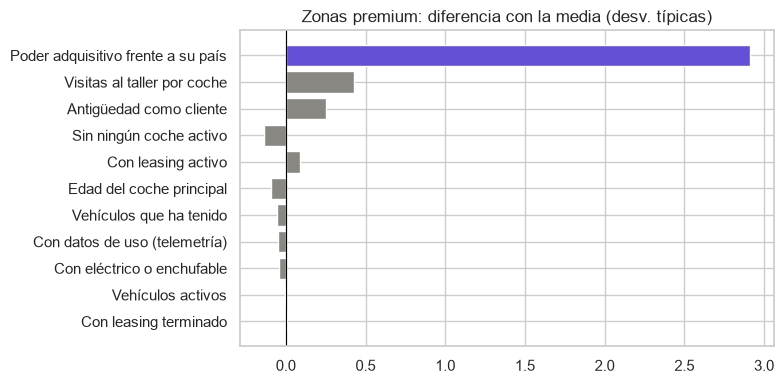

In [16]:
ficha(6)

**Por qué este nombre.** Su rasgo es, con diferencia, el **poder adquisitivo de su zona**: casi el doble del típico de su país. Son casi todos suizos, han usado la garantía más que la media y tienen más gama alta y SUV grandes que la media. Este segmento existe gracias a la variable relativa que creamos en el reto 2 (`ppi_rel`): sin ella, el poder adquisitivo solo habría dicho "es suizo".

## 7. Resumen

Los siete segmentos en una tabla, que es lo que nos llevaríamos a una reunión con marketing:

In [17]:
resumen = pd.DataFrame({
    "segmento": nombres,
    "%": [round(s["pct"], 1) for s in segs],
    "acción": [SEGMENTOS[s["id"]]["accion"] for s in segs],
    "lo que le define": [", ".join(KPIS[k]["label"].lower() for k in s["rasgos"][:2]) for s in segs],
})
resumen

,segmento,%,acción,lo que le define
0,Fieles de taller,24.1,Fidelizar,"visitas al taller por coche, antigüedad como c..."
1,Recién llegados,18.3,Vincular,"antigüedad como cliente, edad del coche principal"
2,Coche veterano,18.2,Renovar,"edad del coche principal, visitas al taller po..."
3,Electrificados,15.9,Acompañar,"con eléctrico o enchufable, edad del coche pri..."
4,Desconectados,9.0,Recuperar,"sin ningún coche activo, vehículos activos"
5,Multivehículo,8.8,Ampliar,"vehículos activos, antigüedad como cliente"
6,Zonas premium,5.6,Elevar,"poder adquisitivo frente a su país, visitas al..."


Tres avisos que hay que tener en la cabeza al usar estos segmentos:

- **"Sin coche activo" es una hipótesis de fuga, no un hecho.** Antes de lanzar una campaña de recuperación a los Desconectados conviene confirmar quién se ha ido de verdad.
- **La antigüedad de 36 meses es un valor por defecto** para un 12 % de los clientes (lo vimos en el EDA). Afecta sobre todo a Coche veterano.
- **Los segmentos hablan de la relación con la marca y del ciclo de vida del coche, no del producto.** La oferta concreta (furgoneta, SUV, gama alta) se ajusta dentro de cada segmento.

## 8. Dashboard

Todo lo de este notebook, en versión interactiva, está en un dashboard: un único fichero HTML que se abre con doble clic en cualquier navegador, sin instalar nada y sin conexión. Lo generamos aquí mismo con las mismas cifras (`src/dashboard.py` usa el mismo perfil). Solo lleva datos agregados por segmento, nunca datos de clientes.

Tiene una vista general (tamaños, mapa de "qué distingue a cada segmento" y un resumen de los siete) y una ficha por segmento con los mismos bloques que hemos visto aquí. Con las flechas ← → del teclado se pasa de un segmento a otro.

In [18]:
from src import dashboard

ruta = dashboard.write_dashboard(clientes, etiquetas)
print("Dashboard generado en", ruta.relative_to(config.ROOT), f"({ruta.stat().st_size / 1024:.0f} KB)")

Dashboard generado en outputs/dashboard_segmentos.html (58 KB)
